# Mortality component attribution

This notebook reconstructs mortality with the fitted hybrid model and decomposes the reconstruction into adaptive baseline, weather-associated, non-COVID SARI-associated, and COVID-19-associated components. It produces the analyses shown in **Manuscript Figure 1** (seasonal component attribution) and **Manuscript Figure 4** (age- and sex-specific attributed mortality).

The temperature counterfactuals preserve relative humidity while capping air temperature at the category boundaries used in the manuscript: 15-20 °C for the optimal range, above 20 °C for heat, and below 0 °C for extreme cold. Component estimates are fitted-model attributions, not registered cause-of-death counts.

## Execution mode

Set `EXECUTION_DEVICE` in the first code cell to `"auto"`, `"cpu"`, or `"cuda"`. Auto mode uses CUDA when available and CPU otherwise. CPU mode evaluates only the `v0` checkpoint for a faster exploratory run; CUDA mode evaluates the complete 10-checkpoint ensemble used for manuscript results.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate the repository root')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from model.containers import MortalityModelInputs
from notebooks import DATA_DIR, load_checkpoint, load_experiment, resolve_device

EXECUTION_DEVICE = "auto"
DEVICE = resolve_device(EXECUTION_DEVICE)

In [ ]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({
    "font.family": "serif",
    "font.sans-serif": ["Arial"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "lines.linewidth": 1.2,
    "grid.alpha": 0.4,
})

## Load the hybrid-model ensemble

The selected experiment combines population-weighted air temperature, dew-point temperature, non-COVID SARI, COVID-19-associated SARI, and the adaptive median-EWMA baseline. Registered daily deaths are aggregated nationally for comparison with reconstructed mortality.

In [3]:
# model loading
experiment_name = 'HeatMortality_EXP_t_6_sari_10_covid_median_ewma_corr_on_pop_average_tas-tdew_stage1'
model, checkpoint_paths = load_experiment(experiment_name, DEVICE)
val = torch.cat([model.train_labels.daily_land, model.val_labels.daily_land]).sum([1]).cpu()

## Define temperature counterfactuals

Counterfactual weather tensors cap observed air temperature at 20 °C, 15 °C, 0 °C, or the 15-20 °C optimal range while adjusting dew point to preserve the original relative humidity. A fixed 16 °C and 50% relative-humidity tensor provides the internal neutral-temperature reference.

In [4]:
# dew point and relative humidity functions
a = 17.27
b = 237.7  # Celsius

def dew_point(T, RH=50):
    alpha = (a * T / (b + T)) + torch.log(RH/100)
    Td = (b * alpha) / (a - alpha)
    return Td

def rel_hum(T, Td):
    alpha = (a * Td / (b + Td)) - (a * T / (b + T))
    RH = 100 * torch.exp(alpha)
    return RH


In [5]:
# temperature input processing

temp = model.temperature_input[:, [0], :].clone()
filter_h = temp > 20
dew_h = model.temperature_input[:, [1]].clone()
dew_h[filter_h] = dew_point(20, rel_hum(temp[filter_h], dew_h[filter_h]))
t_h = temp.clip(max=20)
temp_20 = torch.cat([t_h, dew_h], dim=1)

filter_c = temp < 15
dew_c = model.temperature_input[:, [1]].clone()
dew_c[filter_c] = dew_point(15, rel_hum(temp[filter_c], dew_c[filter_c]))
t_c = temp.clip(min=15)
temp_15 = torch.cat([t_c, dew_c], dim=1)

t_d = temp.clip(min=15, max=20)
dew_d = model.temperature_input[:, [1]].clone()
dew_d[filter_h] = dew_point(20, rel_hum(temp[filter_h], dew_d[filter_h]))
dew_d[filter_c] = dew_point(15, rel_hum(temp[filter_c], dew_d[filter_c]))
temp_15_20 = torch.cat([t_d, dew_d], dim=1)

filter_c = temp < 0
dew_c = model.temperature_input[:, [1]].clone()
dew_c[filter_c] = dew_point(0, rel_hum(temp[filter_c], dew_c[filter_c]))
t_c = temp.clip(min=0)
temp_0 = torch.cat([t_c, dew_c], dim=1)

t_ref = model.temperature_input.clone()
t_ref[:, 0, :] = 16
t_ref[:, 1, :] = dew_point(torch.tensor(16.0), torch.tensor(50.0))

## Evaluate component attribution

Each selected checkpoint is evaluated independently. Online ensemble means are retained for the baseline-scaled weather, non-COVID SARI, and COVID-19 components and for each temperature counterfactual, avoiding storage of every full district-age-sex tensor.

In [6]:
res = []

death_temp_model = None
death_sari = None
death_covid = None

death_temp_20 = None
death_temp_15 = None
death_temp_15_20 = None
death_temp_0 = None
death_temp_ref = None

def update_ensemble_mean(current_mean, value, ensemble_size):
    value = value.detach().cpu()
    if current_mean is None:
        return value
    current_mean += (value - current_mean) / ensemble_size
    return current_mean

for ensemble_size, checkpoint_path in enumerate(checkpoint_paths, start=1):
    load_checkpoint(model, checkpoint_path, DEVICE)
    model.evaluate_baseline()

    with torch.no_grad():
        model._compute_predictions(random_t_sigma=0)

        prediction = model.calculate_mortality(
            model.temperature_input, model.sari_input, model.covid_input, random_t_sigma=0
        )
        res.append(prediction.sum((1, 2, 3)).cpu())

        outputs = model(MortalityModelInputs(
            temperature=model.temperature_input,
            sari=model.sari_input,
            covid=model.covid_input,
        ))

        # deaths attributed to temperature, SARI and COVID effects
        corr = model.get_correction_factors(outputs.temperature_effect.shape)
        current_temp_model = model.get_death_temp_model(outputs.temperature_effect, corr)
        current_sari = model.get_additional_deaths_disease(outputs.sari_effect, corr)
        current_covid = model.get_additional_deaths_disease(outputs.covid_effect, corr)

        current_temp_model = model.apply_training_mean_correction_tensor(current_temp_model)
        current_sari = model.apply_training_mean_correction_tensor(current_sari)
        current_covid = model.apply_training_mean_correction_tensor(current_covid)

        death_temp_model = update_ensemble_mean(death_temp_model, current_temp_model, ensemble_size)
        death_sari = update_ensemble_mean(death_sari, current_sari, ensemble_size)
        death_covid = update_ensemble_mean(death_covid, current_covid, ensemble_size)

        # temperature effect under different temperature input scenarios
        outputs_20 = model(MortalityModelInputs(temperature=temp_20, sari=model.sari_input, covid=model.covid_input))
        death_20 = model.get_death_temp_model(outputs_20.temperature_effect, corr)
        death_20 = model.apply_training_mean_correction_tensor(death_20)
        death_temp_20 = update_ensemble_mean(death_temp_20, death_20, ensemble_size)

        outputs_15 = model(MortalityModelInputs(temperature=temp_15, sari=model.sari_input, covid=model.covid_input))
        death_15 = model.get_death_temp_model(outputs_15.temperature_effect, corr)
        death_15 = model.apply_training_mean_correction_tensor(death_15)
        death_temp_15 = update_ensemble_mean(death_temp_15, death_15, ensemble_size)

        outputs_15_20 = model(MortalityModelInputs(temperature=temp_15_20, sari=model.sari_input, covid=model.covid_input))
        death_15_20 = model.get_death_temp_model(outputs_15_20.temperature_effect, corr)
        death_15_20 = model.apply_training_mean_correction_tensor(death_15_20)
        death_temp_15_20 = update_ensemble_mean(death_temp_15_20, death_15_20, ensemble_size)

        outputs_0 = model(MortalityModelInputs(temperature=temp_0, sari=model.sari_input, covid=model.covid_input))
        death_0 = model.get_death_temp_model(outputs_0.temperature_effect, corr)
        death_0 = model.apply_training_mean_correction_tensor(death_0)
        death_temp_0 = update_ensemble_mean(death_temp_0, death_0, ensemble_size)

        # reference temperature effect
        outputs_ref = model(MortalityModelInputs(temperature=t_ref, sari=model.sari_input, covid=model.covid_input))
        death_ref = model.get_death_temp_model(outputs_ref.temperature_effect, corr)
        death_ref = model.apply_training_mean_correction_tensor(death_ref)
        death_temp_ref = update_ensemble_mean(death_temp_ref, death_ref, ensemble_size)

assert all(value is not None for value in (
    death_temp_model, death_sari, death_covid, death_temp_20, death_temp_15,
    death_temp_15_20, death_temp_0, death_temp_ref,
))

## Prepare respiratory-infection surveillance series

Total SARI incidence is separated into non-COVID SARI and COVID-19-associated SARI. Influenza-specific incidence is retained as an external seasonal reference where available.

In [7]:
sari_path = DATA_DIR / 'sari' / model.config.sari_filename
influenza_file = sari_path
df_sari = pd.read_csv(influenza_file, sep='\t')
df_covid = df_sari[df_sari.SARI=='COVID-19']
df_total = df_sari[df_sari.SARI=='Gesamt']
covid_00 =  df_covid[df_covid.Altersgruppe=='00+'].iloc[::-1,-1].to_numpy()
total_00 = df_total[df_total.Altersgruppe=='00+'].iloc[::-1, -1].to_numpy()[2:]
flu_00 = df_sari[df_sari.SARI=='Influenza'].iloc[::-1, -1].to_numpy()
covid_offset = total_00.shape[0] - covid_00.shape[0]
covid_00 = np.concatenate([np.zeros(covid_offset), covid_00])
flu_offset = total_00.shape[0] - flu_00.shape[0]
flu_00 = np.concatenate([np.zeros(flu_offset), flu_00])
sari_incidence = total_00 - covid_00
covid_incidence = covid_00
flu_incidence = flu_00

## Manuscript Figure 1: Seasonal attribution

The panels show weekly reconstructed mortality components, national SARI surveillance signals, and heat- and cold-associated mortality alongside weekly mean temperature. Vertical component offsets in the first panel are used only for visual separation.

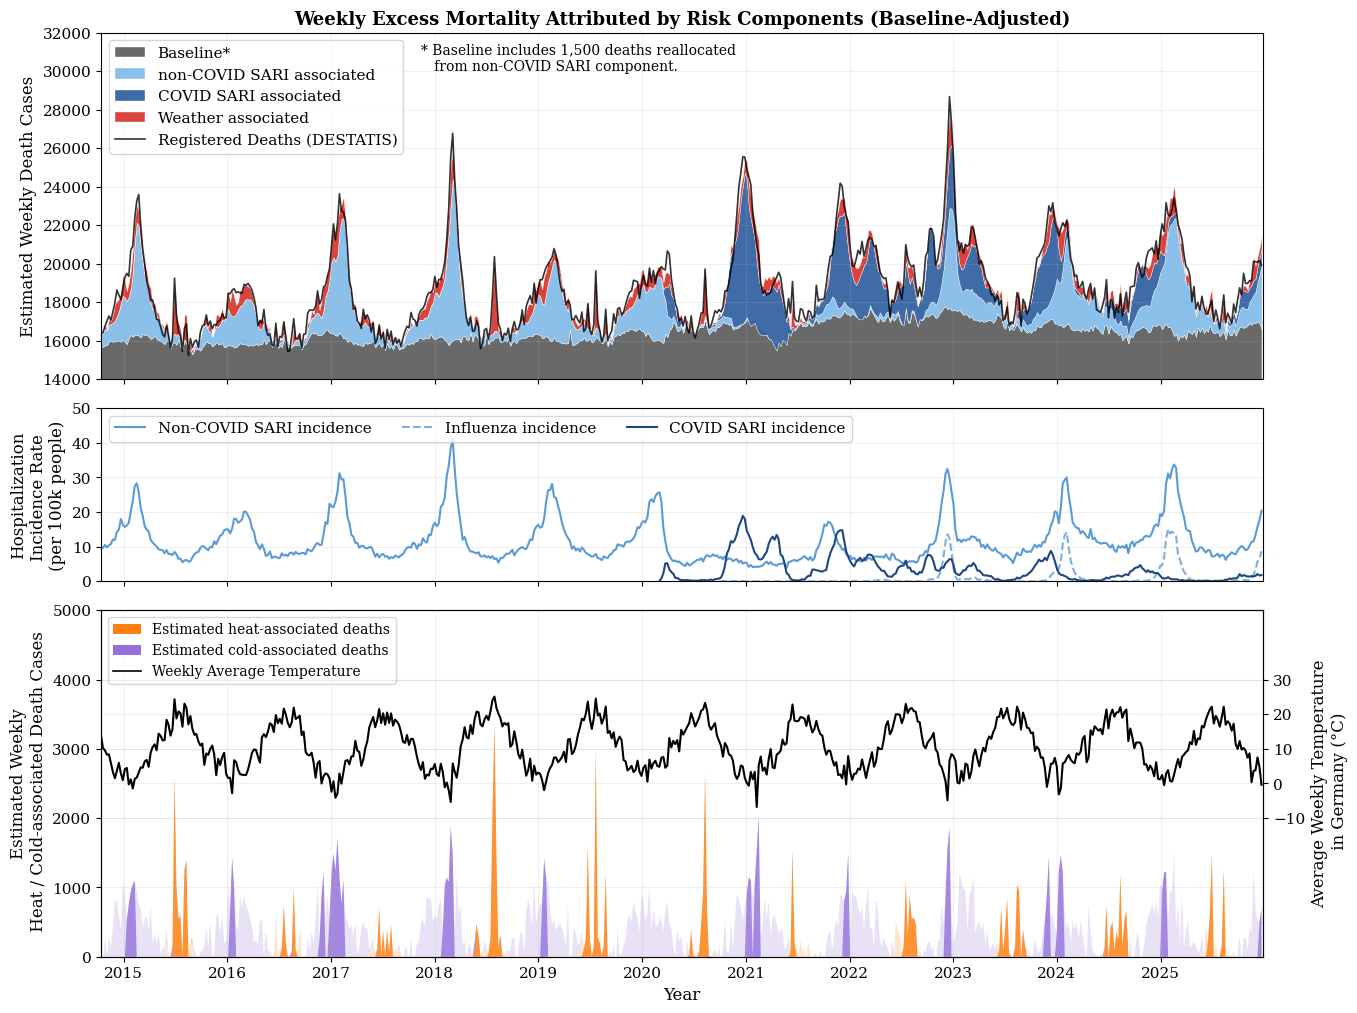

In [8]:
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

death_temp_model_weekly = death_temp_model.sum([1,2,3]).reshape(-1,7).sum(1)
death_sari_weekly = death_sari.sum([1,2,3]).reshape(-1,7).sum(1)
death_covid_weekly = death_covid.sum([1,2,3]).reshape(-1,7).sum(1)
death_temp_additional_weekly = (death_temp_model - death_temp_ref).sum([1,2,3]).reshape(-1,7).sum(1)
death_15_20_weekly = death_temp_15_20.sum([1,2,3]).reshape(-1,7).sum(1)
death_total = torch.stack(res)

c =  [
    '#595959',
    '#7DB9E8',
    '#2A5C9E',
    '#D73027',
]
c2 = ['#5B9BD5', '#5B9BD5', '#1E4780']

data = np.vstack([death_15_20_weekly + 1500, death_sari_weekly - 1500, death_covid_weekly, death_temp_model_weekly - death_15_20_weekly])
fig, ax = plt.subplots(3, 1, figsize=(15, 12), sharex=True,  gridspec_kw=dict(height_ratios=[2, 1, 2], hspace=0.1))
ax[0].stackplot(np.arange(0, data.shape[1]), data,  labels=['Baseline*', 'non-COVID SARI associated', 'COVID SARI associated', 'Weather associated'], alpha=0.9, colors=c, linewidth=0.3, edgecolor='white')
ax[0].grid(True, alpha=0.2)
ax[0].plot(val.reshape(-1,7).sum(1), c='0', lw=1.2, label='Registered Deaths (DESTATIS)', alpha=0.8)
ax[0].legend(loc='upper left')
ax[0].set_title('Weekly Excess Mortality Attributed by Risk Components (Baseline-Adjusted)')

ax[0].text(
    0.275, 0.97,
    '* Baseline includes 1,500 deaths reallocated\n'
    '   from non-COVID SARI component.\n',
    transform=ax[0].transAxes,
    ha='left',
    va='top',
    multialignment='left',
    fontsize=10,
 )

ax[0].set_ylim(14000,32000)
days_cumulative = 80 / 7
ticks = []
for year in range(2015, 2026):
    ticks.append(days_cumulative)
    days_in_year = 366 if (year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)) else 365
    days_cumulative += days_in_year / 7
ax[0].set_xticks(ticks)
ax[0].set_xticklabels([str(y) for y in range(2015, 2026)], fontsize=12)
ax[0].set_xlim(0, death_total.mean(0).shape[0]//7)
ax[0].set_ylabel('Estimated Weekly Death Cases')

ax[1].grid(True, alpha=0.2)
ax[1].plot(np.arange(0, data.shape[1]), sari_incidence[:data.shape[1]], color=c2[0], label='Non-COVID SARI incidence', lw=1.5)
ax[1].plot(np.arange(flu_offset, data.shape[1]), flu_incidence[flu_offset:data.shape[1]], color=c2[1], label='Influenza incidence', ls='--', alpha=0.8, lw=1.5)
ax[1].plot(np.arange(covid_offset, data.shape[1]), covid_incidence[covid_offset:data.shape[1]], color=c2[2], label='COVID SARI incidence', lw=1.5)
ax[1].legend(loc='upper left',ncol=3)
ax[1].set_ylim(0, 50)
ax[1].set_ylabel('Hospitalization\nIncidence Rate \n(per 100k people)')

d_heat = (death_temp_model - death_temp_20)
d_cold = (death_temp_model - death_temp_15)
d_heat_weekly = d_heat.sum([1,2,3]).reshape(-1,7).sum(1)
d_cold_weekly = d_cold.sum([1,2,3]).reshape(-1,7).sum(1)

t_week = model.temperature_input.mean(0)[0].cpu()[5:].reshape(-1,7).mean(1)

data = np.vstack([d_heat_weekly, d_cold_weekly])
mask = ((t_week > 0) & (t_week < 20))
mask_mid = mask[1:-1] & mask[:-2] & mask[2:]
result = torch.zeros_like(t_week, dtype=torch.bool)
result[1:-1] = mask_mid
data_extrem = data.copy()
data_extrem[:, result.numpy()] = 0

ax[2].stackplot(np.arange(0, data.shape[1]), data,  linewidth=0, labels=['heat-associated', 'cold-associated'], alpha=0.2, colors=['tab:orange', 'mediumpurple'])
ax[2].stackplot(np.arange(0, data.shape[1]), data_extrem,  linewidth=0, labels=['heat-associated', 'cold-associated'], alpha=0.8, colors=['tab:orange', 'mediumpurple'])
ax[2].grid(True, alpha=0.2)
ax[2].set_ylim(0, 5000)
ax[2].set_ylabel('Estimated Weekly\n Heat / Cold-associated Death Cases')
ax[2].set_xlabel('Year')

twinx = ax[2].twinx()
twinx.plot(t_week, color='0', lw=1.5)
twinx.set_ylim(-50, 50)
twinx.set_yticks([-10, 0, 10, 20, 30])
twinx.grid(True, alpha=0.2)
twinx.set_ylabel('Average Weekly Temperature\n in Germany (°C)')

custom_lines = [
    Patch(facecolor='tab:orange', edgecolor='none'),
    Patch(facecolor='mediumpurple', edgecolor='none'),
    Line2D([0], [0], color='0', linestyle='-'),
]
legend_labels = ['Estimated heat-associated deaths', 'Estimated cold-associated deaths', 'Weekly Average Temperature']
ax[2].legend(custom_lines, legend_labels, loc='upper left', fontsize=10)

# plt.savefig('stacked_excess_new.png', bbox_inches='tight', dpi=300)
plt.show()

## Manuscript Figure 4: Age- and sex-specific attribution

Attributed counts and population-normalized rates are summarized for 2020-2025 by five-year age group and sex. Respiratory-infection-associated mortality combines non-COVID and COVID-19 components; temperature panels distinguish heat and extreme-cold periods.

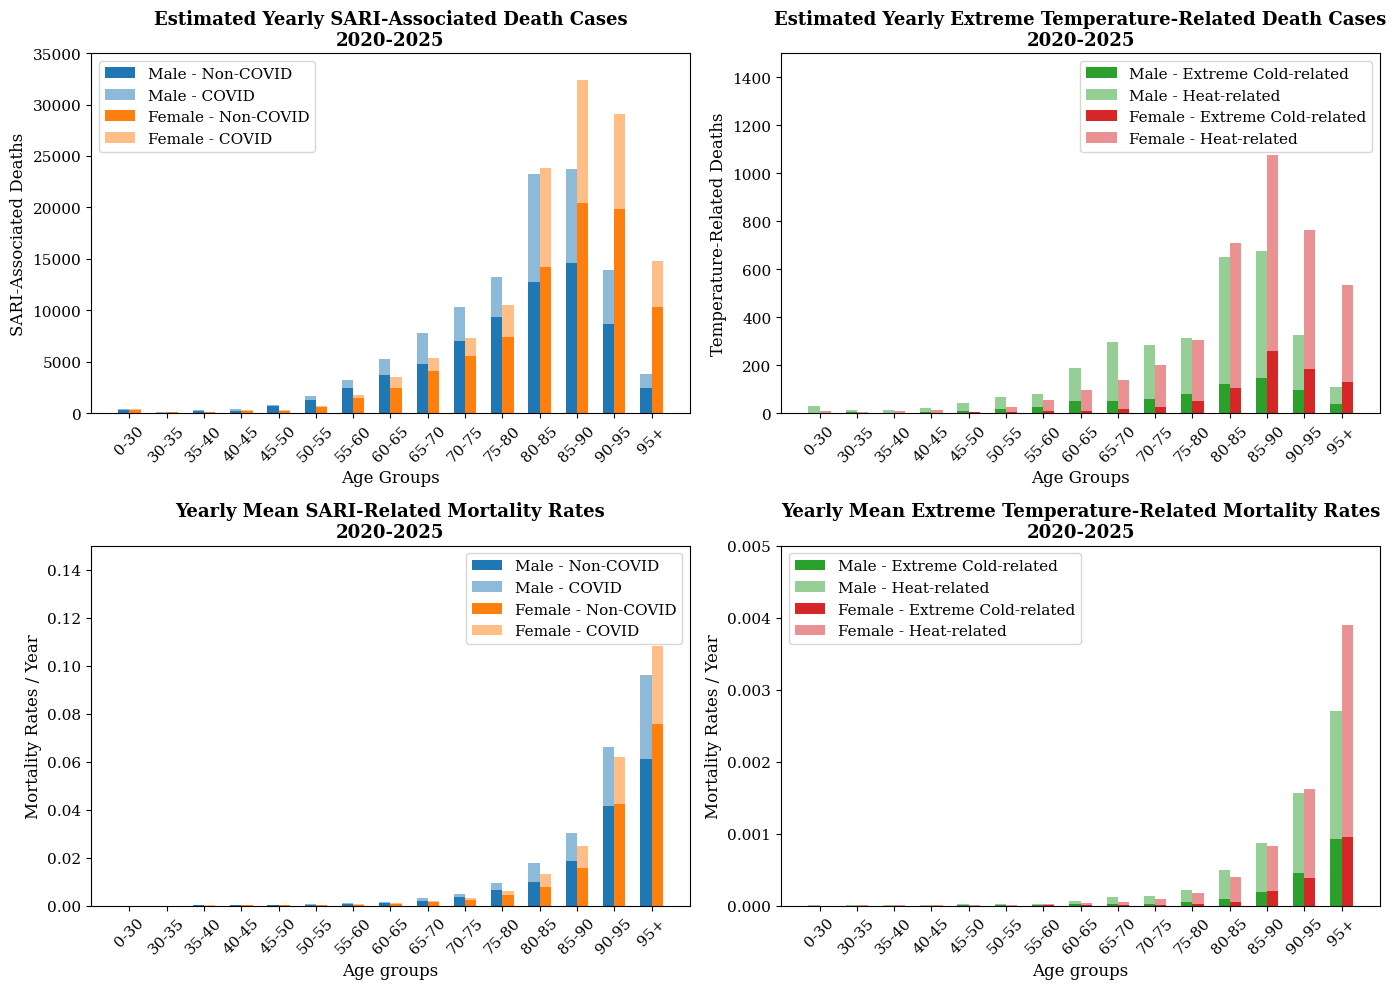

In [9]:
from matplotlib import colormaps
tmp1 = death_sari[80 + 365*5:].sum([0,1])
tmp2 = death_covid[80 + 365*5:].sum([0,1]) 

tmp4 = (death_temp_model - death_temp_20)[80 + 365*5:].sum([0,1]) 
tmp3 = (death_temp_model - death_temp_0)[80 + 365*5:].sum([0,1])  

# Data for the plot
large_groups = ['0-30'] + [f'{i}-{i+5}' for i in range(30, 95, 5)] + ['95+']
small_groups = ['Male', 'Female']

tab10 = colormaps.get_cmap('tab10')
n_large_groups = len(large_groups)
n_small_groups = len(small_groups)

# Bar width
bar_width = 0.3

# X positions for the groups
x = np.arange(n_large_groups)

# Create the plot
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for i, subgroup in enumerate(small_groups):
    # Bottom values for stacking
    bottoms = np.zeros(15)

    ax[0][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp1[:, i] / 5,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=bottoms,                  # Previous layer's heights
        label=f"{subgroup} - Non-COVID" ,  # Label only for the first group
        color=tab10.colors[i]
    )
    ax[0][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp2[:, i] / 5,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=tmp1[:, i] / 5,                  # Previous layer's heights
        label=f"{subgroup} - COVID",  # Label only for the first group
        color=tab10.colors[i],
        alpha = 0.5
    )
    ax[0][1].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp3[:, i] / 5,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=bottoms,                  # Previous layer's heights
        label=f"{subgroup} - Extreme Cold-related",  # Label only for the first group
        color=tab10.colors[i+2]
    )
    ax[0][1].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp4[:, i] / 5,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=tmp3[:, i] / 5,                  # Previous layer's heights
        label=f"{subgroup} - Heat-related",  # Label only for the first group
        color=tab10.colors[i+2],
        alpha = 0.5
    )

# Customize the plot
ax[0][0].set_xlabel('Age Groups')
ax[0][0].set_ylabel('SARI-Associated Deaths')
ax[0][0].set_title('Estimated Yearly SARI-Associated Death Cases\n2020-2025')
ax[0][0].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[0][0].set_xticklabels(large_groups)
ax[0][0].tick_params(axis='x', labelrotation=45)
ax[0][0].legend()

ax[0][1].set_xlabel('Age Groups')
ax[0][1].set_ylabel('Temperature-Related Deaths')
ax[0][1].set_title('Estimated Yearly Extreme Temperature-Related Death Cases\n2020-2025')
ax[0][1].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[0][1].set_xticklabels(large_groups)
ax[0][1].tick_params(axis='x', labelrotation=45)
ax[0][1].legend()

pop = model.population[-1826:].sum(1).mean(0)

# Create the plot
for i, subgroup in enumerate(small_groups):
    # Bottom values for stacking
    bottoms = np.zeros(15)

    ax[1][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp1[:, i] / pop[:, i] / 1826 * 365,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=bottoms,                  # Previous layer's heights
        label=f"{subgroup} - Non-COVID" ,  # Label only for the first group
        color=tab10.colors[i]
    )
    ax[1][0].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp2[:, i]  / pop[:, i] / 1826 * 365,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=tmp1[:, i]  / pop[:, i] / 1826 * 365,                  # Previous layer's heights
        label=f"{subgroup} - COVID",  # Label only for the first group
        color=tab10.colors[i],
        alpha = 0.5
    )
    ax[1][1].bar( 
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp3[:, i] / pop[:, i] / 1826 * 365,          # Heights of the stack layers
        bar_width,                       # Width of the bars
        bottom=bottoms,                  # Previous layer's heights
        label=f"{subgroup} - Extreme Cold-related" ,  # Label only for the first group
        color=tab10.colors[i+2]
    )
    ax[1][1].bar(
        x + i * bar_width,                # Adjust positions for each subgroup
        tmp4[:, i]  / pop[:, i] / 1826 * 365,          # Heights of the stack layers
        bar_width,                       # Width of the bars    
        bottom=tmp3[:, i] / pop[:, i] / 1826 * 365,                  # Previous layer's heights
        label=f"{subgroup} - Heat-related" ,  # Label only for the first group
        color=tab10.colors[i+2],
        alpha = 0.5
    )

# Customize the plot
ax[1][0].set_xlabel('Age groups')
ax[1][0].set_ylabel('Mortality Rates / Year')
ax[1][0].set_title('Yearly Mean SARI-Related Mortality Rates\n2020-2025')
ax[1][0].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[1][0].set_xticklabels(large_groups)
ax[1][0].legend()
ax[1][0].tick_params(axis='x', labelrotation=45)

ax[1][1].set_xlabel('Age groups')
ax[1][1].set_ylabel('Mortality Rates / Year')
ax[1][1].set_title('Yearly Mean Extreme Temperature-Related Mortality Rates\n2020-2025')
ax[1][1].set_xticks(x + bar_width / 2)  # Center the ticks for the grouped bars
ax[1][1].set_xticklabels(large_groups)
ax[1][1].legend()
ax[1][1].tick_params(axis='x', labelrotation=45)

ax[0][0].set_ylim(0, 35000)
ax[0][1].set_ylim(0, 1500)
ax[1][0].set_ylim(0, 0.15)
ax[1][1].set_ylim(0, 0.005)

# ax2 = ax[1].twinx()

# ax2.plot(np.arange(2,15), (tmp2[:, 0] / (tmp1[:, 0] + tmp2[:, 0]))[2:], label='M - COVID / all SARI Deaths')
# ax2.plot(np.arange(2,15), (tmp2[:, 1] / (tmp1[:, 1] + tmp2[:, 1]))[2:], label='F - COVID / all SARI Deaths')
# ax2.set_ylabel("ratio of COVID-deaths")

handles1, labels1 = ax[0][0].get_legend_handles_labels()  # Bars legend
# handles2, labels2 = ax2.get_legend_handles_labels()    # Lines legend

# Combine both legends into one
# ax[1].legend(handles1 + handles2, labels1 + labels2, loc='upper left')


# Show the plot
plt.tight_layout()
# plt.show()
# plt.savefig('mortality_age_structure_2.png', bbox_inches='tight', dpi=300)